## 2D vs 3D plane fitting to GB

In [390]:
import numpy as np
import matplotlib.pyplot as plt
#import itertools
import pandas as pd

### Read normal vectors to basal plane for the grains of interest (c-axis):
#### 1- In Paraview, click in the corresponding grain and read voxel info "normal_vector_to_basal_plane" 
#### 2- Insert below the result with the format [Y, -Z, X]

In [391]:
# c-axis vectors of grains forming OR with hydrides, obtained from dream3d pipeline:
caxis_OR_vector= {
    'Hyd 1-p1': [-0.520, -0.833, 0.185],
    'Hyd 1-p2': [-0.520, -0.833, 0.185],
    'Hyd 2-p1': [-0.072, - 0.631, -0.772],
    'Hyd 2-p2': [-0.072, - 0.631, -0.772],
    'Hyd 3-p1': [0.486, -0.857, 0.172],
    'Hyd 3-p2': [0.486, -0.857, 0.172],
    'Hyd 4-p1': [0.486, -0.857,  0.172],
    'Hyd 4-p2': [0.486, -0.857,  0.172],
    'Hyd 5-p1': [-0.430, -0.778, -0.458],
    'Hyd 5-p2': [-0.430, -0.778, -0.458],
    'Hyd 6': [0.279, -0.957, 0.073],
    'Hyd 7': [0.343, -0.924, -0.169],
    'Hyd 8': [-0.002, -0.489, -0.872],
    'Hyd 9': [0.242, -0.325, -0.914]
}

### Do the plane fitting in Paraview and insert the vector of that plane here:

In [392]:
# 2D plane fitting: Vectors perpendicular to the planes fitted to GB, measured in Paraview
normal_vector2D= {
    'Hyd 1-p1': [0.999, 0.0386, 0],
    'Hyd 1-p2': [0.993, 0.118, 0],
    'Hyd 2-p1': [0.978, 0.206, 0],
    'Hyd 2-p2': [0.800, 0.600, 0],
    'Hyd 3-p1':[0.439, -0.899, 0],
    'Hyd 3-p2':[0.058, -0.996, 0],
    'Hyd 4-p1':[0.694, 0.718, 0],
    'Hyd 4-p2':[-0.459, -0.889, 0],
    'Hyd 5-p1':[0.170, -0.985, 0],
    'Hyd 5-p2':[0.247, -0.969, 0],
    'Hyd 6':[0.997, -0.0808, 0],
    'Hyd 7':[-0.103, 0.995, 0],
    'Hyd 8':[0.996, 0.0936, 0],
    'Hyd 9':[0.895, 0.445, 0]
}

In [393]:
# 3D plane fitting: Vectors perpendicular to the planes fitted to GB, measured in Paraview
normal_vector3D= {
    'Hyd 1-p1': [0.950, 0.175, 0.258],
    'Hyd 1-p2': [0.984, 0.016, 0.176],
    'Hyd 2-p1': [-0.661, -0.113, 0.741],
    'Hyd 2-p2': [-0.526, -0.496, 0.691],
    'Hyd 3-p1':[0.456, -0.872, 0.182],
    'Hyd 3-p2':[0.0314, -0.986, 0.167],
    'Hyd 4-p1':[0.679, 0.732, -0.057],
    'Hyd 4-p2':[0.380, 0.899, -0.219],
    'Hyd 5-p1':[0.249, -0.954, -0.169],
    'Hyd 5-p2':[0.178, -0.961, -0.212],
    'Hyd 6':[-0.365,0.037,0.930],
    'Hyd 7':[-0.019, 0.118, 0.993],
    'Hyd 8':[0.706, 0.113, 0.699],
    'Hyd 9':[0.411, 0.165, 0.897]
}

### Calculate the angle between the two vectors:


In [394]:
# Function to calculate the angle between two vectors:

def angle(n, b): # θ=arctan2(∥n×b∥,|n⋅b|)
    dot = np.dot(n, b)
    normcross = np.linalg.norm(np.cross(n, b))
    dot = abs(dot)  # make angle insensitive to sign flips
    # Use atan2 for better numerical stability than arccos
    return np.degrees(np.arctan2(normcross, dot))

In [395]:
# Calculate angle between c-axis vector and normal vector to GBs from 2D and 3D plane fitting:

angles_OR2D = {}
angles_OR3D = {}
angles_OR2D_large = {}
angles_OR3D_large = {}


for h in caxis_OR_vector:
    angles_OR2D[h] = int(np.round(angle(caxis_OR_vector[h], normal_vector2D[h])))
    angles_OR3D[h] = int(np.round(angle(caxis_OR_vector[h], normal_vector3D[h])))


labels = list(angles_OR2D.keys())
values2D = list(angles_OR2D.values())
values3D = list(angles_OR3D.values())


In [396]:
values2D

[56, 52, 78, 64, 11, 28, 74, 57, 46, 50, 69, 17, 87, 86]

In [397]:
values3D

[54, 60, 63, 79, 2, 27, 72, 51, 45, 40, 86, 74, 48, 39]

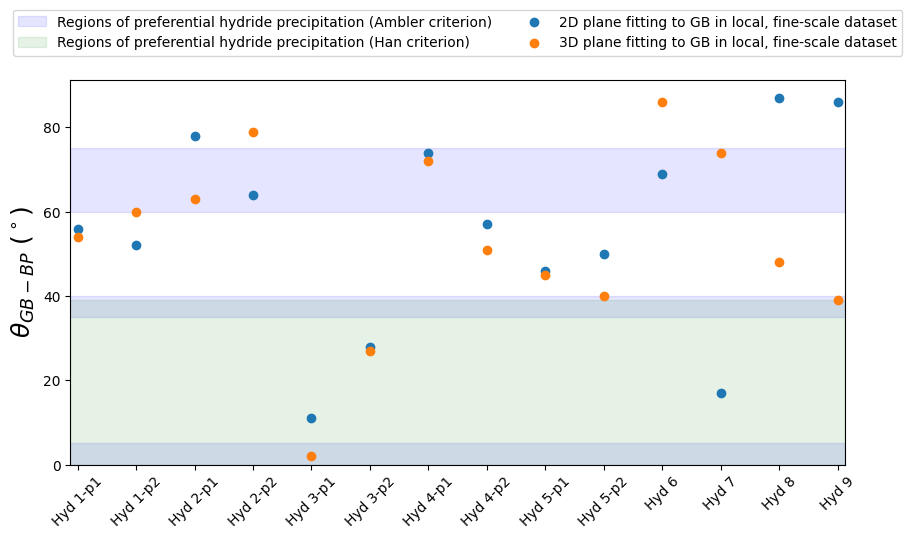

In [398]:
# Plotting the angles and comparing 2D vs 3D plane fitting for three hydrides:
plt.figure(figsize=(10, 5))

# Ambler critetion:
plt.axhspan(60, 75, color='blue', alpha=0.1, label='Regions of preferential hydride precipitation (Ambler criterion)')
plt.axhspan(35, 40, color='blue', alpha=0.1)
plt.axhspan(0, 5, color='blue', alpha=0.1)

# Han criterion:
plt.axhspan(0, 39, color='green', alpha=0.1, label='Regions of preferential hydride precipitation (Han criterion)')

plt.scatter(labels, values2D, label="2D plane fitting to GB in local, fine-scale dataset")
plt.scatter(labels, values3D, label="3D plane fitting to GB in local, fine-scale dataset")

plt.ylabel(r'$\theta_{GB-BP}\ (^\circ)$', fontsize=18)

plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.2), ncol=2)
plt.margins(x=0.01)

plt.ylim(bottom=0)
plt.xticks(rotation=45)

plt.show()

### Comparing two different plane fitting:

In [399]:
caxis_vector={
    'Hydride 1': [-0.520, -0.833, 0.185],
    'Hydride 6':[0.279, -0.957, 0.073],
    'Hydride 8': [-0.002, -0.489, -0.872]
    #'Hydride 9': [0.242, -0.325, -0.914]
}

In [400]:
normal_vector2D_horizontal= {
    'Hydride 1': [0.999, 0.0386, 0],
    'Hydride 6':[0.997, -0.0808, 0],
    'Hydride 8':[0.996, 0.0936, 0]
    #'Hydride 9':[0.895, 0.445, 0]
}

In [401]:
normal_vector2D_vertical= {
    'Hydride 1': [0.0244, 0.7444,0.667],
    'Hydride 6':[-0.059, -0.01, 0.998],
    'Hydride 8':[0.0145, 0.0598, 0.998],
    #'Hydride 9':[0.019, 0.136, 0.99]
}

In [402]:
normal_vector3D= {
    'Hydride 1': [0.950, 0.175, 0.258],
    'Hydride 6':[-0.365,0.037,0.930],
    'Hydride 8':[0.706, 0.113, 0.699],
    #'Hydride 9':[0.411, 0.165, 0.897 ]
}

In [403]:
# Calculate angle between c-axis vector and normal vector to GBs from 2D and 3D plane fitting:

angles_OR2D_horizontal = {}
angles_OR2D_vertical = {}
angles_OR3D = {}

for h in caxis_vector:
    angles_OR2D_horizontal[h] = int(np.round(angle(caxis_vector[h], normal_vector2D_horizontal[h])))
    angles_OR2D_vertical[h] = int(np.round(angle(caxis_vector[h], normal_vector2D_vertical[h])))
    angles_OR3D[h] = int(np.round(angle(caxis_vector[h], normal_vector3D[h])))


labels = list(angles_OR2D_horizontal.keys())
values2D_horizontal = list(angles_OR2D_horizontal.values())
values2D_vertical = list(angles_OR2D_vertical.values())
values3D = list(angles_OR3D.values())

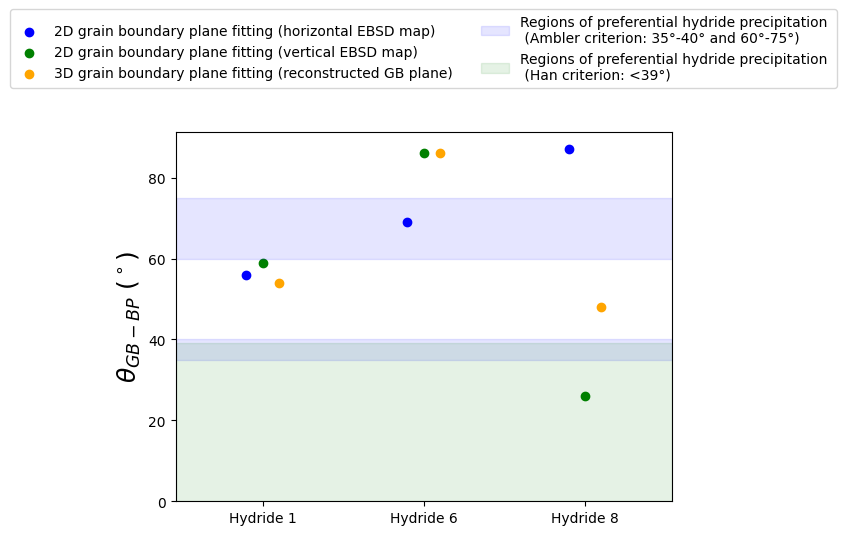

In [404]:
# Plotting the angles and comparing 2D vs 3D plane fitting for three hydrides:
plt.figure()

x = np.arange(len(labels))
offset = 0.1

plt.scatter(x-offset, values2D_horizontal, color='blue',label="2D grain boundary plane fitting (horizontal EBSD map)")
plt.scatter(x, values2D_vertical, color='green', label="2D grain boundary plane fitting (vertical EBSD map)")
plt.scatter(x+offset, values3D,color='orange', label="3D grain boundary plane fitting (reconstructed GB plane)")

# Ambler critetion:
plt.axhspan(60, 75, color='blue', alpha=0.1, label='Regions of preferential hydride precipitation \n (Ambler criterion: 35°-40° and 60°-75°)')
plt.axhspan(35, 40, color='blue', alpha=0.1)



#plt.axhspan(0, 5, color='blue', alpha=0.1)

# Han criterion:
plt.axhspan(0, 39, color='green', alpha=0.1, label='Regions of preferential hydride precipitation \n (Han criterion: <39°)')

#Liu criterion:
#plt.axhspan(0, 70,hatch='\\\\', color='grey', alpha=0.1, label='Regions of preferential hydride precipitation \n (Liu criterion: <70°)')

plt.ylabel(r'$\theta_{GB-BP}\ (^\circ)$', fontsize=18)

plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.35), ncol=2)
plt.margins(x=0.2)

plt.ylim(bottom=0)
plt.xticks(x, labels)

plt.show()